# Step 1: Install Required Libraries
In this step, we install all the necessary dependencies for building and evaluating our RAG (Retrieval-Augmented Generation) pipeline. This includes packages for document loading (`pypdf`), text splitting (`langchain`), vector search (`faiss-cpu`), LLM orchestration (`langchain-community`, `groq`), embeddings (`sentence-transformers`), and RAG evaluation (`ragas`).

In [1]:
# Install the libraries required for RAG
!pip install -U sentence-transformers faiss-cpu langchain langchain-community pypdf langchain-text-splitters langchain-groq numpy python-dotenv rank-bm25 streamlit fastapi uvicorn ragas

# Step 2: Upload Documents
Here we prompt the user to upload a PDF file (e.g., *Introducing MLOps* book). This file serves as the external knowledge base from which the RAG system retrieves answers.

In [3]:
from google.colab import files
uploaded =files.upload()

for filename in uploaded.keys():
    print(f"Uploaded : {filename}")


Saving introduction-of-mlops.pdf to introduction-of-mlops (1).pdf
Uploaded : introduction-of-mlops (1).pdf


# Step 3: Document Ingestion
Using `PyPDFLoader` from LangChain, we load the uploaded PDF into memory. This extracts the text content page-by-page so we can split and process it.

In [4]:
# Data ingestion
from langchain_community.document_loaders import PyPDFLoader
pdf_file = list(uploaded.keys())[0]

loader = PyPDFLoader(pdf_file)
documents = loader.load()
print("Number of the pages loaded : " ,len(documents))


Number of the pages loaded :  185


# Step 4: Preview Ingested Document
We print out a sample page (in this case, page 5 containing the Table of Contents) to verify that the PDF text and metadata have been parsed correctly.

In [5]:
print(documents[5])

page_content='Data Sources and Exploratory Data Analysis                                                        24
Feature Engineering and Selection                                                                          25
Training and Evaluation                                                                                            26
Reproducibility                                                                                                           26
Responsible AI                                                                                                            26
Productionalization and Deployment                                                                        27
Model Deployment Types and Contents                                                                28
Model Deployment Requirements                                                                           29
Monitoring                                                                               

# Step 5: Document Chunking
Since PDFs are too large to pass into LLM context windows entirely, we split the parsed documents into smaller, manageable pieces (chunks) of `500` characters with a `100` character overlap. This retains context across splits.

In [6]:
# Chunking
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(chunk_size =500, chunk_overlap = 100)
chunks = text_splitter.split_documents(documents)
print("Number of chunks : " ,len(chunks))

Number of chunks :  1048


# Step 6: Preview Chunks
We inspect the list of generated chunks to ensure that the content is split properly and retains metadata like source name and page number.

In [7]:
chunks

[Document(metadata={'producer': 'Antenna House PDF Output Library 6.2.609 (Linux64)', 'creator': 'AH CSS Formatter V6.2 MR4 for Linux64 : 6.2.6.18551 (2014/09/24 15:00JST)', 'creationdate': '2020-11-30T15:55:35+00:00', 'author': 'Mark Treveil and the Dataiku Team', 'moddate': '2020-11-30T11:53:24-05:00', 'title': 'Introducing MLOps', 'trapped': '/False', 'source': 'introduction-of-mlops (1).pdf', 'total_pages': 185, 'page': 1, 'page_label': 'Dataiku'}, page_content='Test\nVertica\nTrain\nHDFS_Avro Joined_Data\nHDFS_Parquet\nCassandra\nOracle\nTeradata\n2\nAmazon_S3\nTest_Scored\nMLlib_Prediction\nNetwork_dataset\n2\nMatt\nBUSINESS ANALYST\nAlivia\nDATA SCIENTIST\nAlex\nDATA ENGINEER\nMastering MLops\nwith Dataiku\n1\n2\n3\n4\nKEY FEATURES FOR A SCALABLE MLOPS STRATEGY INCLUDE:\nModel input drift detection that looks at the recent data the model has had to \nscore and statistically compares it with the data on which the model was \nevaluated.'),
 Document(metadata={'producer': 'Antenna 

# Step 7: Text Embedding & Indexing (FAISS)
Using the `all-MiniLM-L6-v2` Sentence Transformer, we map each text chunk to a high-dimensional vector space (384 dimensions). These vectors are then stored in a `FAISS` index for fast L2-distance-based similarity search.

In [8]:
# Embedding from the chunk
import faiss
import numpy as np
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("all-MiniLM-L6-v2")

#embedding
embedding = model.encode([chunk.page_content for chunk in chunks])
dimension = embedding.shape[1]

# index
index = faiss.IndexFlatL2(dimension)
index.add(np.array(embedding))

print("total vector in the index : ",index.ntotal)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

total vector in the index :  1048


# Step 8: Dimension Check
We inspect the dimension of the embedding vector to ensure it aligns with the expected output (384 dimensions) of the `all-MiniLM-L6-v2` model.

In [9]:
dimension

384

# Step 9: Embedding Visualization Helper
This helper function normalizes vector values and plots them as an 1D heat map. It helps visualize how different text contents map to numeric patterns in vector space.

In [10]:
# !pip install matplotlib
import matplotlib.pyplot as plt

def visualize_embedding(vector, chunk_text = None, max_text_chars=500):
  vector = np.array(vector)

  normalization = (vector - np.min(vector)) / (np.max(vector) - np.min(vector))
  color_band =normalization.reshape(1,-1)

  if chunk_text is not None:
    print("Chunk text \n")
    print(chunk_text[:max_text_chars])
    print("\n")

  plt.figure(figsize=(10,2))
  plt.imshow(color_band, aspect='auto')
  plt.yticks([])
  plt.xlabel(f"Embedding Dimensions ({len(vector)})")
  plt.title("Vector representation")
  plt.show()

# Step 10: Visualize Document Chunk Embedding
Here we visually analyze the 384-dimensional vector of our second chunk using the helper plotting function.

Chunk text 

score and statistically compares it with the data on which the model was 
evaluated.
Easier creation of validation feedback loops via Dataiku Evaluation Recipes to 
compute the true performance of a saved model against a new validation 
dataset, plus automated retraining and redeployment.
Dashboard interfaces dedicated to the monitoring of global pipelines.
...and more! Go in-depth on all the features Dataiku has to oﬀer at 
www.dataiku.com




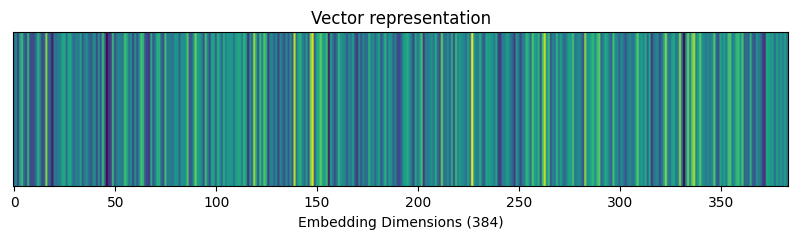

In [11]:
visualize_embedding(embedding[1], chunks[1].page_content)

# Step 11: Prompt Query and Retrieve Vector representation
We take a user query, embed it using the same Sentence Transformer model, and render its vector representation.

Enter your questionwhy are we need to use mlops and what am i get in final improvement


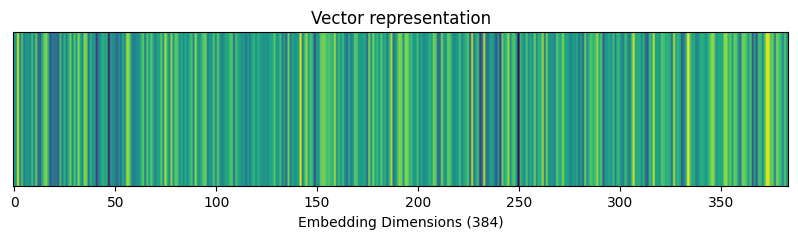

In [12]:
# Retrieval
query = input("Enter your question")
query_embedding = model.encode([query])
query_embedding = np.array(query_embedding)
visualize_embedding(query_embedding[0])

# Step 12: Retrieve Top K Relevant Chunks
We perform a similarity search inside the FAISS index to find the top 5 most similar chunks to the query vector, using L2 distance calculation.

In [ ]:
D,I = index.search(np.array(query_embedding),k=5)

retrieved_chunk =[chunks[i] for i in I[0]]

print("Top retrieved chunks  : \n")

for chunk in retrieved_chunk:
  print(chunk.page_content)
  print("Page",chunk.metadata['page'])
  print("="*50)

Top retrieved chunks  : 

are building. However, there are other MLOps needs as well—specifically around
transparency, which ties into Responsible AI—that are relevant for subject matter
experts and make them an important part of the MLOps picture.
Data Scientists
The needs of data scientists are the most critical ones to consider when building an
MLOps strategy. To be sure, they have a lot to gain; data scientists at most organiza‐
tions today often deal with siloed data, processes, and tools, making it difficult to
Page 30
Ideally, for maximum efficiency for the data engineer profile (and for others as well,
including data scientists), MLOps must not consist of simple monitoring, but be a
bridge to underlying systems for investigating and tweaking ML models.
Data Engineers | 19
Page 32
None of this is news, of course, nor specific to MLOps. What is different with ML is
that it is a new and often opaque technology that carries many risks, but it is rapidly
being embedded in decision-m

# Step 13: Reranking Chunks
To improve retrieval quality, we utilize a Cross-Encoder model (`ms-marco-MiniLM-L6-v2`) to rank the top 5 retrieved chunks based on their relevance to the original user query.

In [ ]:
# Reranking
from sentence_transformers import CrossEncoder

reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2")

pairs = [(query, chunk.page_content) for chunk in retrieved_chunk]
scores = reranker.predict(pairs)

ranked_chunks = sorted(zip(scores, retrieved_chunk), key=lambda x: x[0], reverse=True)

print("After reranking : \n")
for score, chunk in ranked_chunks:
  print("score : ", score)
  print("="*50)
  print(chunk.page_content)
  print("Page", chunk.metadata['page'])
  print("="*50)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

After reranking : 

score :  7.6326513
are building. However, there are other MLOps needs as well—specifically around
transparency, which ties into Responsible AI—that are relevant for subject matter
experts and make them an important part of the MLOps picture.
Data Scientists
The needs of data scientists are the most critical ones to consider when building an
MLOps strategy. To be sure, they have a lot to gain; data scientists at most organiza‐
tions today often deal with siloed data, processes, and tools, making it difficult to
Page 30
score :  6.5176954
CHAPTER 1
Why Now and Challenges
Machine learning operations (MLOps) is quickly becoming a critical component of
successful data science project deployment in the enterprise (Figure 1-1). It’s a process
that helps organizations and business leaders generate long-term value and reduce
risk associated with data science, machine learning, and AI initiatives. Y et it’s a rela‐
tively new concept; so why has it seemingly skyrocketed into 

# Step 14: Combine Top Reranked Context
We take the top 3 highest-ranked chunks and concatenate them into a single coherent context block to feed into our language model.

In [ ]:
# Combine reranked chunk with context
top_chunks = [chunk.page_content for _,chunk in ranked_chunks[:3]]
context ="\n\n".join(top_chunks)
print(context)

are building. However, there are other MLOps needs as well—specifically around
transparency, which ties into Responsible AI—that are relevant for subject matter
experts and make them an important part of the MLOps picture.
Data Scientists
The needs of data scientists are the most critical ones to consider when building an
MLOps strategy. To be sure, they have a lot to gain; data scientists at most organiza‐
tions today often deal with siloed data, processes, and tools, making it difficult to

CHAPTER 1
Why Now and Challenges
Machine learning operations (MLOps) is quickly becoming a critical component of
successful data science project deployment in the enterprise (Figure 1-1). It’s a process
that helps organizations and business leaders generate long-term value and reduce
risk associated with data science, machine learning, and AI initiatives. Y et it’s a rela‐
tively new concept; so why has it seemingly skyrocketed into the data science lexicon

Ideally, for maximum efficiency for the

# Step 14.5: Reusable RAG Pipeline Function
Here we wrap the retrieval, reranking, and generation logic into a single function so that we can easily pass different questions and get responses in one step.

In [16]:
def query_rag(query_text):
    global reranker
    # 1. Embed query
    q_embed = model.encode([query_text])
    q_embed = np.array(q_embed)

    # 2. Retrieve Top 5 chunks using FAISS
    _, I = index.search(q_embed, k=5)
    retrieved = [chunks[i] for i in I[0]]

    # 3. Ensure reranker is initialized
    from sentence_transformers import CrossEncoder
    try:
        reranker
    except NameError:
        reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2")

    # 4. Rerank retrieved chunks with Cross-Encoder
    pairs = [(query_text, chunk.page_content) for chunk in retrieved]
    scores = reranker.predict(pairs)
    ranked = sorted(zip(scores, retrieved), key=lambda x: x[0], reverse=True)

    # 5. Combine top 3 reranked chunks into context
    top_3_chunks = [chunk.page_content for _, chunk in ranked[:3]]
    combined_context = "\n\n".join(top_3_chunks)

    # 6. Generate Answer via Groq
    prompt = f"""
    Answer the question using the context below.
    Context : {combined_context}
    Question : {query_text}
    provide a concise answer.
    if you don't find the info in the context, do not guess, Say that the info is not found in the documents
    """

    from google.colab import userdata
    from groq import Groq

    client = Groq(api_key=userdata.get('GROQ_API_KEY'))

    response = client.chat.completions.create(
        model="qwen/qwen3.8-27b",
        messages=[{"role": "user", "content": prompt}]
    )

    return response.choices[0].message.content

# Quick Demo
test_query = "Who are the critical profiles to consider when building an MLOps strategy?"
test_answer = query_rag(test_query)
print(f"Q: {test_query}\nA: {test_answer}")

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Q: Who are the critical profiles to consider when building an MLOps strategy?
A: Based on the context, the critical profiles include a **diverse group of experts across the organization**, not just data scientists, as well as **upper management and the C-suite**.


# Step 15: Generate Answer using Groq API
Finally, we construct a structured prompt with the retrieved context and question, and send it to an LLM via the Groq API to receive a highly focused, non-hallucinated response.

In [ ]:
from groq import Groq

# 1. Initialize the client (Make sure your GROQ_API_KEY environment variable is set)
from google.colab import userdata
client = Groq(api_key=userdata.get('GROQ_API_KEY'))

# Your context and query variables
# context = "..."
# query = "..."

prompt = f"""
Answer the question using the context below.
Context : {context}
Question : {query}
provide a concise answer.
if you don't find the info in the context, do not guess, Say that the info is not found in the documents
"""

# 2. Use a Groq-supported model and the correct plural 'completions' method
response = client.chat.completions.create(
    model="qwen/qwen3.8-27b",
    messages=[
        {
            "role": "user",
            "content": prompt
        }
    ]
)

answer =response.choices[0].message.content


# Step 16: Display the Final Answer
We print out the finalized output produced by the LLM.

In [ ]:
print(answer)

MLOps is needed to help organizations generate long-term value, reduce the risk associated with data science, machine learning, and AI initiatives, and to bridge the gap between simple monitoring and investigating/tweaking ML models for maximum efficiency.
